# **Teachable Machine**

https://teachablemachine.withgoogle.com/

Se debe crear un proyecto de tipo imagen con imágenes estándar y entrenar al menos dos categorías de imágenes.

Una vez recogidas las dos muestras de entrenamiento, se debe preparar el modelo.

Una vez preparado el modelo se debe exportar usando la opción Tensorflow.js.

La ejecución del código que se ofrece en Javascript permite probar el modelo en local.

La estructura de carpetas de la aplicación en local debe ser la siguiente:


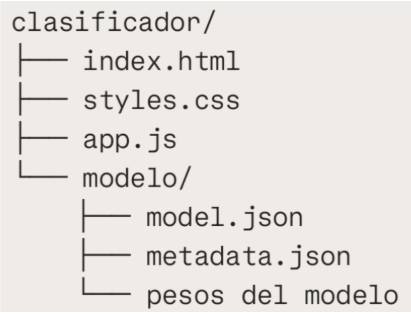

Una vez que funcione el modelo, se deben realizar una serie de mejoras:

* mejorar el diseño de la página
* hacer la página responsive
* poner un botón de inicio y otro de parada
* mostrar un mensaje personalizado de salida
* dejar establecer un valor mínimo a partir del cual se considera que hay una coincidencia
* guardar un histórico de resultados y mostrarlo
* permitir que se suba una imagen para calificarla

Se debe entregar una memoria hecha con Colab en la que se explique textualmente y con capturas todo el proceso.

Tiempo: de 2 a 3 horas de clase.

# **Guarda y exporta**

Guarda el proyecto. Exporta también el modelo tanto para Tensorflow.js como Tensorflow, ya que necesitarás utilizarlo de nuevo en una práctica más adelante.

Práctica 1: Teachable Machine con Javascript

Eduardo Calvo Gea  
Optativa IA


1. Introducción y Recolección de Datos
El objetivo de este proyecto ha sido crear una aplicación web inteligente capaz de diferenciar entre una botella y una caja.
Para el entrenamiento, utilicé la plataforma *Teachable Machine* de Google.



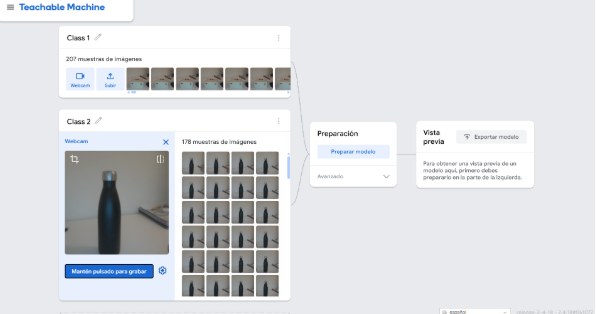



Entrenamiento del Modelo
Una vez recolectadas más de 150 imágenes por clase, procedí a entrenar el modelo. Evalué los resultados en la vista previa comprobando que distinguía correctamente los objetos.

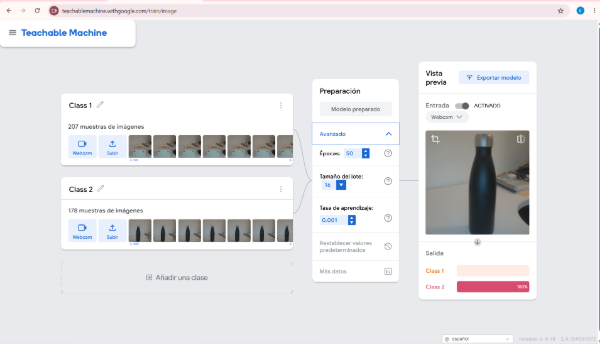

Exportación del Modelo
El modelo se exportó usando dos formatos:
1. **Tensorflow.js:** Para integrarlo en la aplicación web local. Generó los archivos `model.json`, `metadata.json` y `weights.bin`.
2. **TensorFlow (SavedModel):** Lo guardo para usarlo  en futuras prácticas con Python.

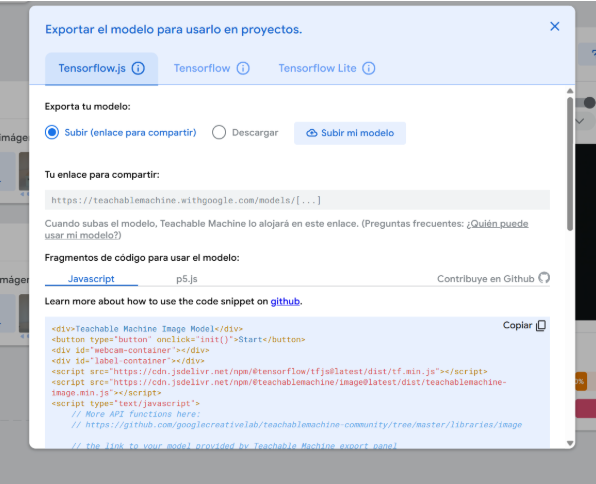

4. Implementación Local y Mejoras Desarrolladas
Construyo una página web estructurada en HTML, CSS y JS, implementando un servidor local. Se añadieron las siguientes mejoras según dice la tarea:
* **Diseño Responsive:** Uso de Flexbox mediante CSS.
* **Controles:** Botones interactivos de "Iniciar" y "Detener" cámara.
* **Mensaje de Salida:** Se muestra un panel visual  dependiendo si la IA reconoce un objeto.
* **Control de Umbral (Sensibilidad):** Un *slider* permite al usuario decidir qué porcentaje de seguridad (0 a 100%) es necesario para dar el resultado por válido.
* **Historial:** Un array guarda las últimas 5 detecciones en tiempo real.
* **Subida de Archivos:** Integración de un `<input type="file">` y un `FileReader` para analizar imágenes estáticas del disco duro en lugar de la webcam.

Codigo HTML:


```
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Clasificador de Imágenes Inteligente</title>
    <link rel="stylesheet" href="style.css">
    <!-- Librerías de TensorFlow.js y Teachable Machine -->
    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
</head>
<body>
    <div class="container">
        <header>
            <h1>IA: Clasificador de Imágenes</h1>
            <p>Usa tu cámara web o sube una imagen para evaluar el modelo.</p>
        </header>

        <section class="controls">
            <div class="buttons">
                <button id="btn-start" onclick="init()">▶ Iniciar Cámara</button>
                <button id="btn-stop" onclick="stopWebcam()" disabled>⏹ Detener Cámara</button>
            </div>
            
            <div class="settings">
                <label for="threshold">Sensibilidad (Umbral de coincidencia): <span id="threshold-val">0.80</span></label>
                <input type="range" id="threshold" min="0" max="1" step="0.05" value="0.80">
            </div>

            <div class="upload-area">
                <label for="image-upload" class="upload-btn">📁 Subir Imagen Manual</label>
                <input type="file" id="image-upload" accept="image/*" style="display: none;">
            </div>
        </section>

        <section class="main-display">
            <!-- Contenedores de Imagen -->
            <div id="visual-container">
                <div id="webcam-container"></div>
                <img id="uploaded-image" alt="Imagen subida">
            </div>

            <!-- Resultados -->
            <div class="results-panel">
                <h3>Análisis en tiempo real</h3>
                <div id="label-container"></div>
                <div id="custom-message" class="waiting">Esperando datos...</div>
            </div>
        </section>

        <section class="history-section">
            <h3>Historial de Coincidencias</h3>
            <ul id="history-list"></ul>
        </section>
    </div>

    <script src="script.js"></script>
</body>
</html>
```



Código CSS para darle estiloa la página:



```
:root {
    --primary: #4285f4;
    --danger: #ea4335;
    --success: #34a853;
    --bg-color: #f4f7f6;
    --text-color: #333;
}

body {
    font-family: 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
    background-color: var(--bg-color);
    color: var(--text-color);
    margin: 0;
    padding: 20px;
}

.container {
    max-width: 900px;
    margin: 0 auto;
    background: white;
    padding: 30px;
    border-radius: 12px;
    box-shadow: 0 4px 15px rgba(0,0,0,0.1);
}

header { text-align: center; margin-bottom: 30px; }

/* Responsive Grid / Flexbox */
.controls, .main-display {
    display: flex;
    flex-wrap: wrap;
    gap: 20px;
    margin-bottom: 30px;
    align-items: center;
    justify-content: center;
}

button, .upload-btn {
    padding: 10px 20px;
    border: none;
    border-radius: 6px;
    cursor: pointer;
    font-weight: bold;
    color: white;
    transition: 0.3s;
}

#btn-start { background-color: var(--primary); }
#btn-stop { background-color: var(--danger); }
button:disabled { opacity: 0.5; cursor: not-allowed; }
.upload-btn { background-color: #5f6368; display: inline-block;}

.settings {
    display: flex;
    flex-direction: column;
    align-items: center;
    background: #e8f0fe;
    padding: 10px 20px;
    border-radius: 8px;
}

#visual-container {
    flex: 1;
    min-width: 300px;
    display: flex;
    justify-content: center;
    background: #000;
    border-radius: 8px;
    overflow: hidden;
}

#uploaded-image {
    max-width: 100%;
    max-height: 400px;
    display: none;
}

.results-panel {
    flex: 1;
    min-width: 250px;
    background: #fafafa;
    padding: 20px;
    border-radius: 8px;
    border: 1px solid #ddd;
}

#custom-message {
    margin-top: 15px;
    padding: 15px;
    border-radius: 6px;
    font-weight: bold;
    text-align: center;
}
.success { background-color: #d4edda; color: #155724; }
.waiting { background-color: #fff3cd; color: #856404; }

.history-section {
    background: #f8f9fa;
    padding: 15px;
    border-radius: 8px;
}
#history-list {
    list-style-type: none;
    padding: 0;
    max-height: 150px;
    overflow-y: auto;
}
#history-list li {
    padding: 8px;
    border-bottom: 1px solid #ddd;
    font-size: 0.9em;
}




```



Código JS:



```
const URL = "./modelo/";

let model, webcam, labelContainer, maxPredictions;
let isPlaying = false;
let historyArray = [];
let lastHistoryTime = 0;

// Cargar el modelo de imagen
async function loadModel() {
    if (!model) {
        const modelURL = URL + "model.json";
        const metadataURL = URL + "metadata.json";
        model = await tmImage.load(modelURL, metadataURL);
        maxPredictions = model.getTotalClasses();
        
        labelContainer = document.getElementById("label-container");
        labelContainer.innerHTML = "";
        for (let i = 0; i < maxPredictions; i++) {
            labelContainer.appendChild(document.createElement("div"));
        }
    }
}

// Iniciar WebCam
async function init() {
    await loadModel();
    document.getElementById("uploaded-image").style.display = "none";
    document.getElementById("webcam-container").style.display = "block";

    const flip = true;
    webcam = new tmImage.Webcam(400, 400, flip);
    await webcam.setup();
    await webcam.play();
    
    isPlaying = true;
    window.requestAnimationFrame(loop);

    document.getElementById("webcam-container").innerHTML = "";
    document.getElementById("webcam-container").appendChild(webcam.canvas);

    document.getElementById("btn-start").disabled = true;
    document.getElementById("btn-stop").disabled = false;
}

// Detener WebCam
function stopWebcam() {
    if (webcam && isPlaying) {
        webcam.stop();
        isPlaying = false;
        document.getElementById("btn-start").disabled = false;
        document.getElementById("btn-stop").disabled = true;
    }
}

// Bucle de cámara
async function loop() {
    if (isPlaying) {
        webcam.update();
        await predict(webcam.canvas);
        window.requestAnimationFrame(loop);
    }
}

// Subida manual de imagen
document.getElementById('image-upload').addEventListener('change', async function(e) {
    stopWebcam();
    await loadModel();
    
    const file = e.target.files[0];
    if (file) {
        const reader = new FileReader();
        reader.onload = function(event) {
            const imgElement = document.getElementById('uploaded-image');
            imgElement.src = event.target.result;
            imgElement.style.display = 'block';
            document.getElementById('webcam-container').style.display = 'none';
            
            imgElement.onload = async function() {
                await predict(imgElement);
            }
        }
        reader.readAsDataURL(file);
    }
});

// Actualizar visualización del umbral
document.getElementById('threshold').addEventListener('input', function(e) {
    document.getElementById('threshold-val').innerText = parseFloat(e.target.value).toFixed(2);
});

// Función central de predicción
async function predict(imageElement) {
    const predictions = await model.predict(imageElement);
    const threshold = parseFloat(document.getElementById('threshold').value);
    
    let bestMatch = { className: "", probability: 0 };

    // Mostrar barras y buscar el mejor resultado
    for (let i = 0; i < maxPredictions; i++) {
        const probResult = predictions[i].probability.toFixed(2);
        labelContainer.childNodes[i].innerHTML = `${predictions[i].className}: ${(probResult * 100).toFixed(0)}%`;
        
        if (predictions[i].probability > bestMatch.probability) {
            bestMatch = predictions[i];
        }
    }

    const customMessage = document.getElementById('custom-message');
    
    // Evaluar coincidencia con el umbral establecido
    if (bestMatch.probability >= threshold) {
        customMessage.innerText = `¡Detectado! Es un(a) "${bestMatch.className}" ✅`;
        customMessage.className = "success";
        addToHistory(bestMatch.className, bestMatch.probability);
    } else {
        customMessage.innerText = "Ninguna coincidencia supera el umbral establecido ⏳";
        customMessage.className = "waiting";
    }
}

// Guardar historial (con un pequeño retardo para no saturar al usar cámara)
function addToHistory(className, prob) {
    const now = Date.now();
    // Solo registra máximo 1 vez por segundo
    if (now - lastHistoryTime < 1000) return;
    lastHistoryTime = now;
    
    const time = new Date().toLocaleTimeString();
    const item = `[${time}] ${className} - ${(prob * 100).toFixed(1)}% de seguridad`;
    
    historyArray.unshift(item);
    if(historyArray.length > 5) historyArray.pop(); // Guardar solo los últimos 5
    
    const list = document.getElementById('history-list');
    list.innerHTML = "";
    historyArray.forEach(text => {
        const li = document.createElement("li");
        li.innerText = text;
        list.appendChild(li);
    });
}
```



Además podemos activar la cámara de nuestro ordenador para poder ver en tiempo real e identificar si lo que ponemos frente a la camara es una caja o una botella, y si algo no es una botella tiene un limitador que tu regulas para que puedas controlar que porcentaje es el mínimo para que detecte que uno u otro objeto


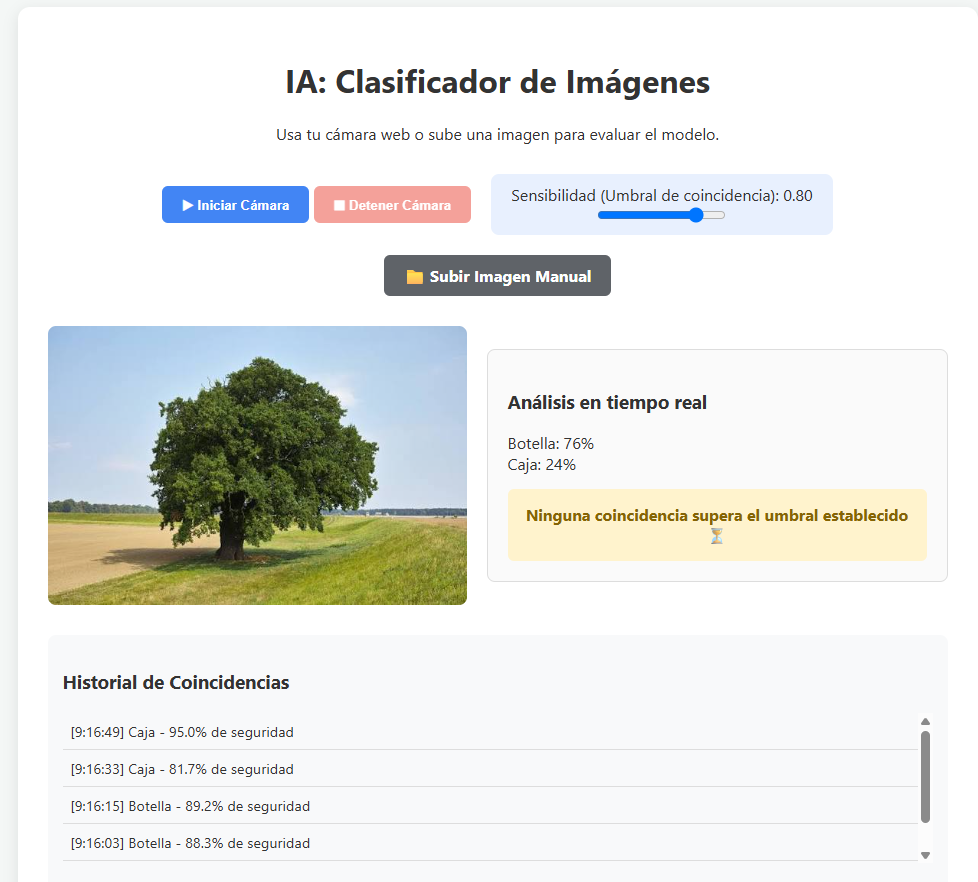



Algunas Imagenes de la pargina funcionando perfectamente en nuestro puerto 8080:

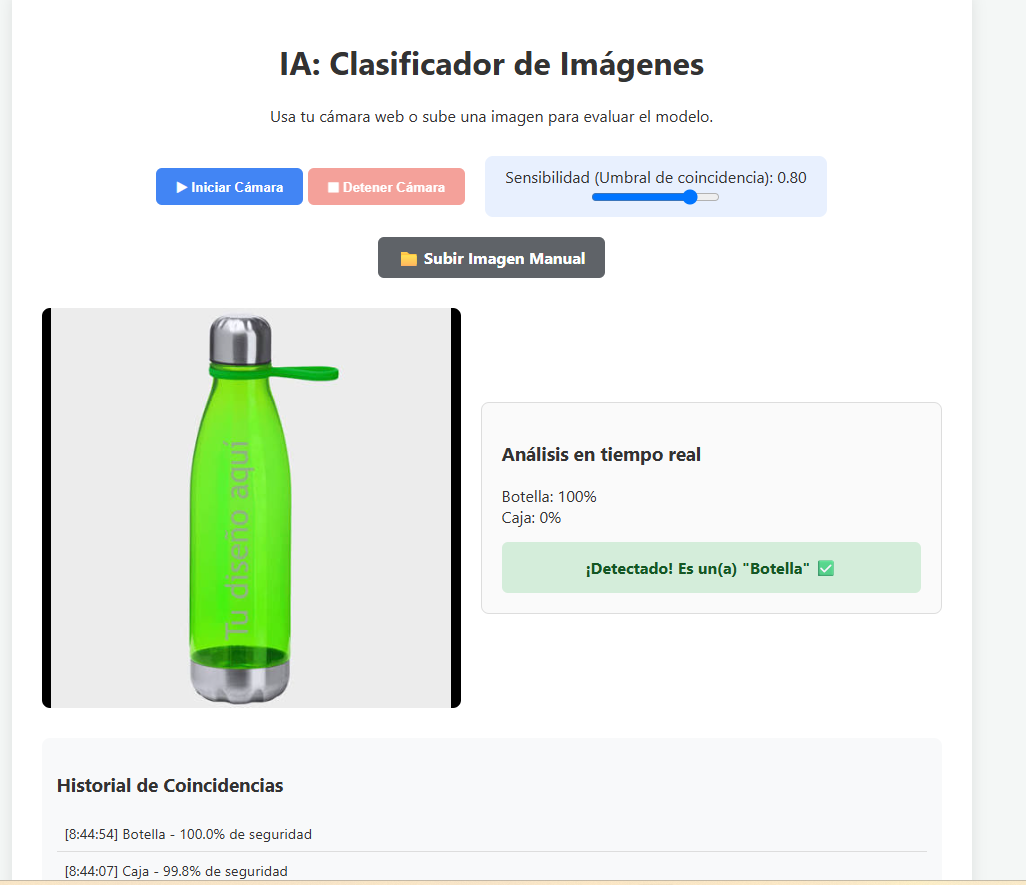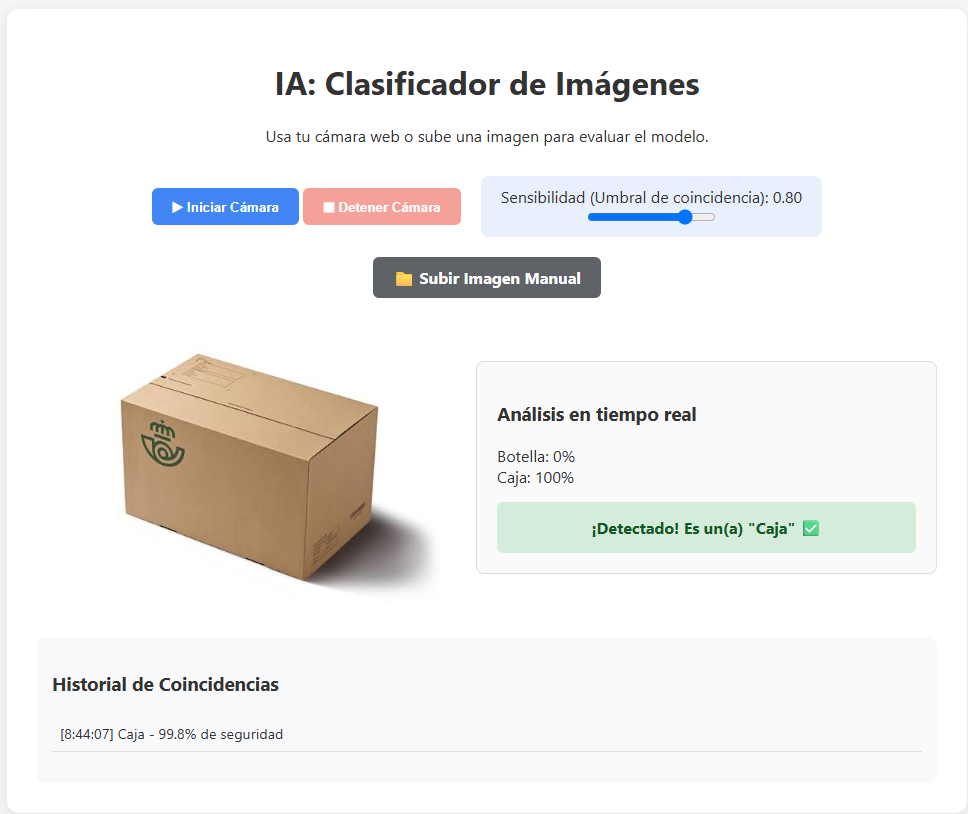